# Tutorial 10 — Spectrum of a sparse graph

Notebook of the programming section of chapter 10 of R. Kühn, P. Vivo and F. Zamponi,
*Introduction to statistical physics for non-physicists* (Oxford University Press).

The matrix $M$ is built on a random $c$-regular graph with $N$ vertices, with $M_{ij}=1/\sqrt{c}$ on every
edge. Its regularised spectral density $\rho_\varepsilon(\lambda)$ is computed in two ways, by numerical
diagonalisation and by solving the cavity equations, and its dependence on $\varepsilon$ and $N$ is studied.

**How to run it.** Run all cells from top to bottom, locally (Jupyter) or on Google Colab:
[open it in Colab](https://colab.research.google.com/github/francescozamponi/statphys-tutorials/blob/main/Tutorial_10/Tutorial_10.ipynb).
No data files are needed. The random graphs are generated with a fixed seed, so that the notebook
reproduces the figures of the book. The cavity calculation takes about two minutes.

In [2]:
import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import sys, urllib.request
%matplotlib inline

BOOK_REPO = 'https://raw.githubusercontent.com/francescozamponi/statphys-tutorials/main/'

# Book formatting: every figure is saved at its printed size, so that all text prints at the
# same size in the book (bookfig.py; it does not change the plots). Without bookfig.py the
# figures are saved as they are.
sys.path[:0] = ['..', '../Figs_generator']
try:
    from bookfig import setup, save, HALF, SINGLE, FULL
except ImportError:                         # e.g. on Colab: fetch bookfig.py from the book repository
    try:
        urllib.request.urlretrieve(BOOK_REPO + 'bookfig.py', 'bookfig.py')
        from bookfig import setup, save, HALF, SINGLE, FULL
    except Exception:
        setup = None
if setup:
    setup()
else:
    HALF, SINGLE, FULL = 0.49, 0.7, 1.0
    def save(path, width, **kw):
        plt.savefig(path, bbox_inches='tight')

## Regularised density from numerical diagonalisation

`diag_sparse` builds $M$ on a random $c$-regular graph (generated with the given `seed`) and returns its
eigenvalues $\lambda_\alpha$; `rho_smooth` computes
$\rho_{{\rm exact},\varepsilon}(\lambda) = \frac{1}{\pi N}\sum_\alpha \frac{\varepsilon}{(\lambda-\lambda_\alpha)^2+\varepsilon^2}$.

In [4]:
def diag_sparse(c, N, seed):
    G = nx.random_regular_graph(c, N, seed)
    nb = [list(G.neighbors(i)) for i in range(N)]
    M = np.zeros((N, N), dtype=float)
    for i, j in G.edges():
        M[i, j] = M[j, i] = 1.0 / np.sqrt(c)
    return np.linalg.eigvalsh(M)

def rho_smooth(lam_grid, evals, eps):
    rho_exact = np.zeros_like(lam_grid)
    for q, lam in enumerate(lam_grid):
        rho_exact[q] = np.mean( eps / ((lam - evals)**2 + eps**2) ) / np.pi
    return rho_exact

## Cavity equations

The cavity variables $v_j^{(i)}$ live on the directed edges $j\to i$ and are found by (damped) iteration of
$v_j^{(i)} = 1/\big[\mathrm{i}(\lambda-\mathrm{i}\varepsilon) + \sum_{\ell\in\partial j\setminus i} M_{j\ell}^2 v_\ell^{(j)}\big]$;
then $v_i = 1/\big[\mathrm{i}(\lambda-\mathrm{i}\varepsilon) + \sum_{j\in\partial i} M_{ij}^2 v_j^{(i)}\big]$ and
$\rho_{{\rm cav},\varepsilon}(\lambda) = \frac{1}{\pi N}\,\mathrm{Re}\sum_i v_i$.

In [6]:
def cavity(c, N, seed, eps, eta, lam_grid):
    # directed edges and an index for every message j -> i
    G = nx.random_regular_graph(c, N, seed)
    nb = [list(G.neighbors(i)) for i in range(N)]
    edges = [(j, i) for j in range(N) for i in nb[j]]
    idx = {e: a for a, e in enumerate(edges)}

    rho_cav = np.zeros_like(lam_grid)
    w2 = 1.0 / c              # M_ij^2
    for q, lam in enumerate(lam_grid):
        # i(lambda-i eps) = eps + i lambda
        v = np.full(len(edges), 1.0 / (eps + 1j*lam), dtype=complex)

        for it in range(max_iter):
            v_upd = np.empty_like(v)
            for a, (j, i) in enumerate(edges):
                s = 0.0j
                for ell in nb[j]:
                    if ell != i:
                        s += w2 * v[idx[(ell, j)]]
                v_upd[a] = 1.0 / (eps + 1j*lam + s)

            v_new = (1.0 - eta)*v + eta*v_upd
            if np.max(np.abs(v_new - v)) < tol:
                v = v_new
                break
            v = v_new

        v_site = np.empty(N, dtype=complex)
        for i in range(N):
            s = sum(w2 * v[idx[(j, i)]] for j in nb[i])
            v_site[i] = 1.0 / (eps + 1j*lam + s)

        rho_cav[q] = np.real(v_site).mean() / np.pi
    return rho_cav

## Parameters

In [8]:
N = 1000
c = 4
eps = 0.05
eta = 0.5                 # damping
tol = 1e-10
max_iter = 1000
seed = 1

evals = diag_sparse(c,N,seed)
lam_grid = np.linspace(evals.min() - 0.5,evals.max() + 0.5, 500)

## Cavity versus diagonalisation (question 3)

In [10]:
rho_cav = cavity(c, N, seed, eps, eta, lam_grid)

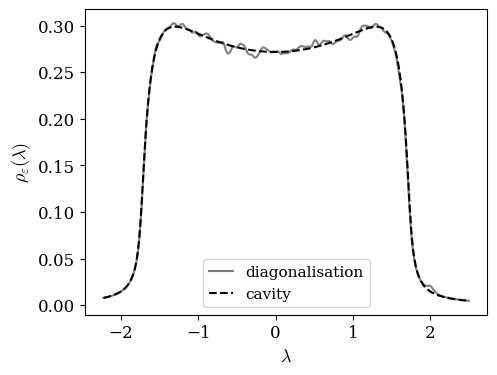

In [11]:
plt.plot(lam_grid, rho_smooth(lam_grid,evals,eps), label='diagonalisation', color='grey')
plt.plot(lam_grid, rho_cav, label='cavity', linestyle='--', color='black')
plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\rho_\varepsilon(\lambda)$')
plt.legend()
plt.tight_layout()
save('cavity_vs_exact.pdf', SINGLE)
plt.show()

## Effect of $\varepsilon$ at fixed $N$ (question 1)

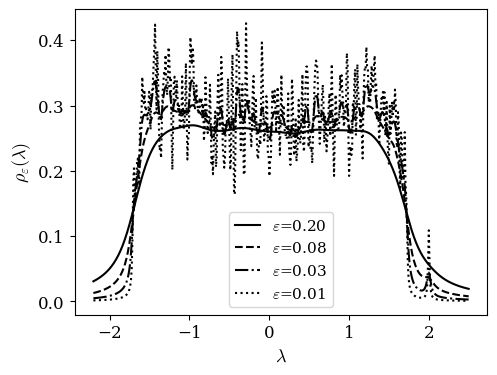

In [13]:
N = 300

evals = diag_sparse(c,N,seed)
lam_grid = np.linspace(evals.min() - 0.5,evals.max() + 0.5, 500)

plt.plot(lam_grid, rho_smooth(lam_grid,evals,0.20), label=r'$\varepsilon$=0.20', color='black')
plt.plot(lam_grid, rho_smooth(lam_grid,evals,0.08), label=r'$\varepsilon$=0.08', linestyle='--', color='black')
plt.plot(lam_grid, rho_smooth(lam_grid,evals,0.03), label=r'$\varepsilon$=0.03', linestyle='-.', color='black')
plt.plot(lam_grid, rho_smooth(lam_grid,evals,0.01), label=r'$\varepsilon$=0.01', linestyle=':', color='black')
#plt.plot(lam_grid, rho_cav, '--', label='cavity', color='black')
plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\rho_\varepsilon(\lambda)$')
plt.legend()
plt.tight_layout()
save('epsilon_effect.pdf', SINGLE)
plt.show()

## Effect of $N$ at fixed $\varepsilon$ (questions 2 and 4)

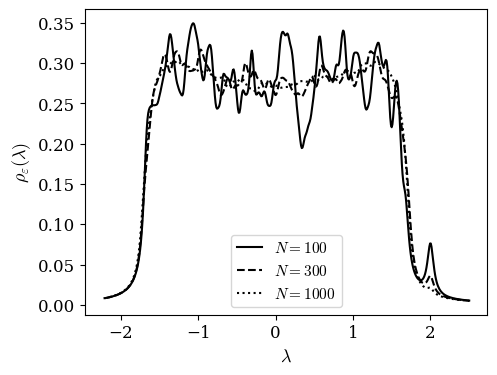

In [15]:
styles = ['-', '--', ':']

for N, ls in zip([100, 300, 1000], styles):
    evals = diag_sparse(c,N,seed)
    lam_grid = np.linspace(evals.min() - 0.5, evals.max() + 0.5, 500)
    plt.plot(lam_grid, rho_smooth(lam_grid, evals, 0.05),
             label=rf'$N={N}$', color='black', linestyle=ls)

plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\rho_\varepsilon(\lambda)$')
plt.legend()
plt.tight_layout()
save('N_effect.pdf', SINGLE)
plt.show()